29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Accuracy: 0.96


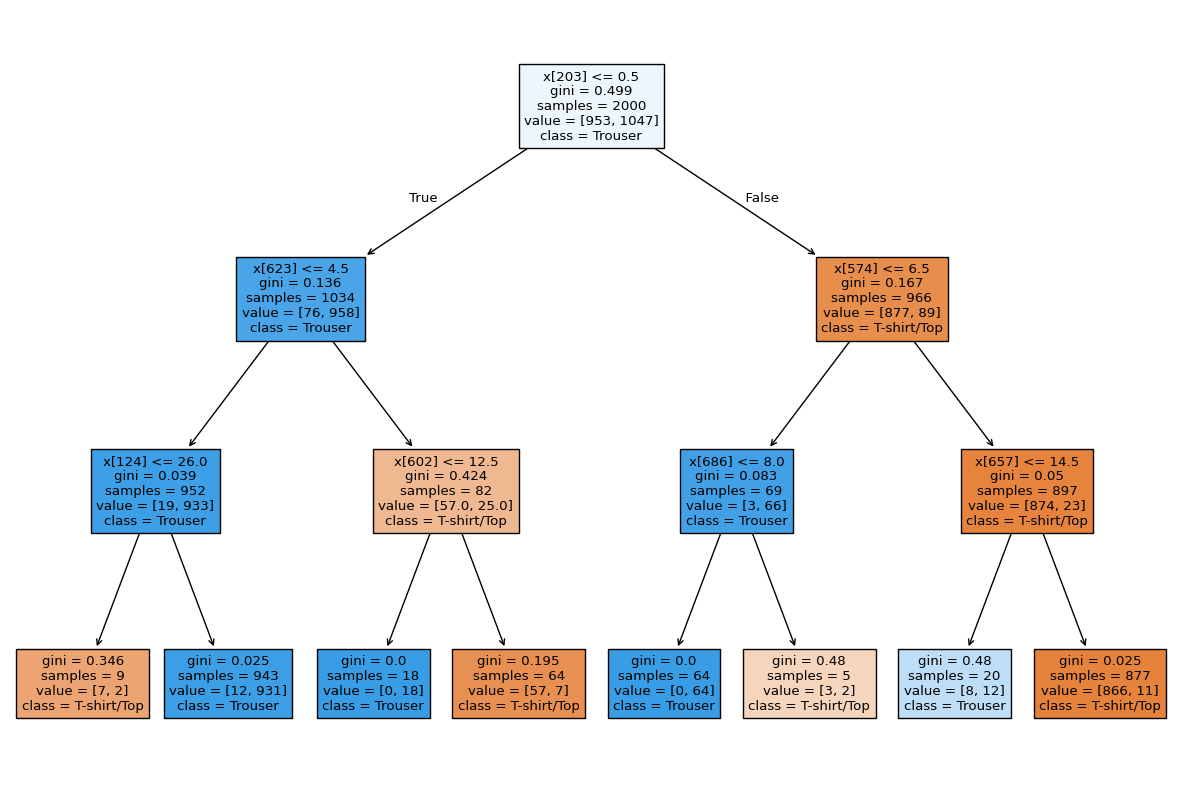

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# Load Fashion-MNIST image dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Use only two classes:
# 0 = T-shirt/top
# 1 = Trouser

train_mask = (y_train == 0) | (y_train == 1)
test_mask = (y_test == 0) | (y_test == 1)

X_train = X_train[train_mask]
y_train = y_train[train_mask]

X_test = X_test[test_mask]
y_test = y_test[test_mask]

# Use a smaller number of images for faster execution
X_train = X_train[:2000]
y_train = y_train[:2000]

X_test = X_test[:500]
y_test = y_test[:500]

# Convert 28 x 28 images into 784 pixel features
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

# Create CART Decision Tree
clf = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

# Train the classifier
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Calculate accuracy
accuracy = clf.score(X_test, y_test)

print("Accuracy:", accuracy)

# Visualize the Decision Tree
plt.figure(figsize=(15, 10))

tree.plot_tree(
    clf,
    max_depth=3,
    filled=True,
    class_names=["T-shirt/Top", "Trouser"]
)

plt.show()